In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from sklearn.decomposition              import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
from clustering.clusteringTimeSeries    import ClusteringTimeSeries

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
preData.additionEfficiencyVar()
preData.splitTimeSeries()
preData.getHealthyState()
df      = preData.crusher1

scaler  = MinMaxScaler() 
preData.normalizeData(scaler=scaler);

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:394: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod], ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:394: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod], ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\

In [3]:
linePlot(data   = df, 
         x      = 'tiempo', 
         y      = 'corriente(A)', 
         color  = 'trajectory')

In [24]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfEfficiencyVar = preData.scaledCrusher1[preData.efficiencyCr1] # + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(eps=2.6, min_samples=60, n_jobs=-1),
                       'pacmap': DBSCAN(eps=3,   min_samples=60, n_jobs=-1)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components=2),
                       'pacmap': pacmap.PaCMAP(n_components=2, save_tree=True)}

In [25]:
Clusters = ClusteringTimeSeries(data                = preData.crusher1, 
                                dataNormalized      = dfEfficiencyVar, 
                                clusteringModels    = clusteringModels, 
                                dimReductionModels  = dimReductionModels)

In [26]:
# Train dimensinality reduction models wiht a trajectory
Clusters.train(trainTrajectory='15')

In [27]:
# Clusters are calculated in embedding space
Clusters.getResults()

100%|██████████| 6/6 [00:24<00:00,  4.09s/it]


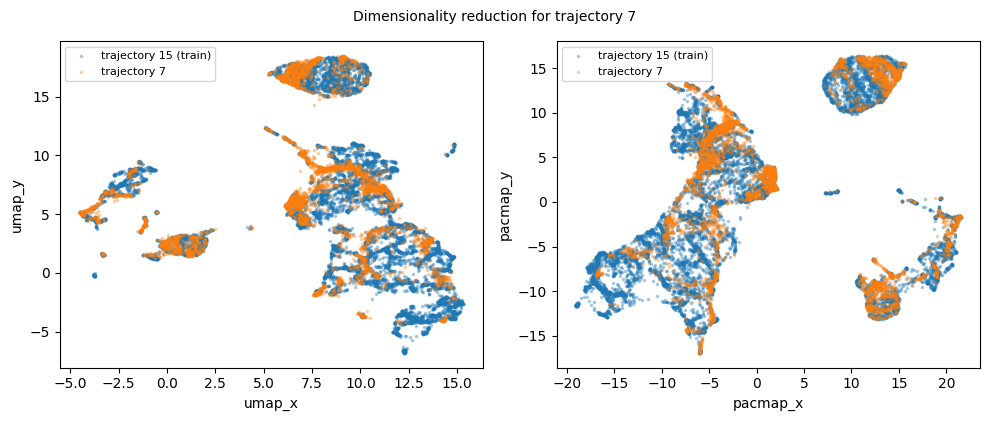

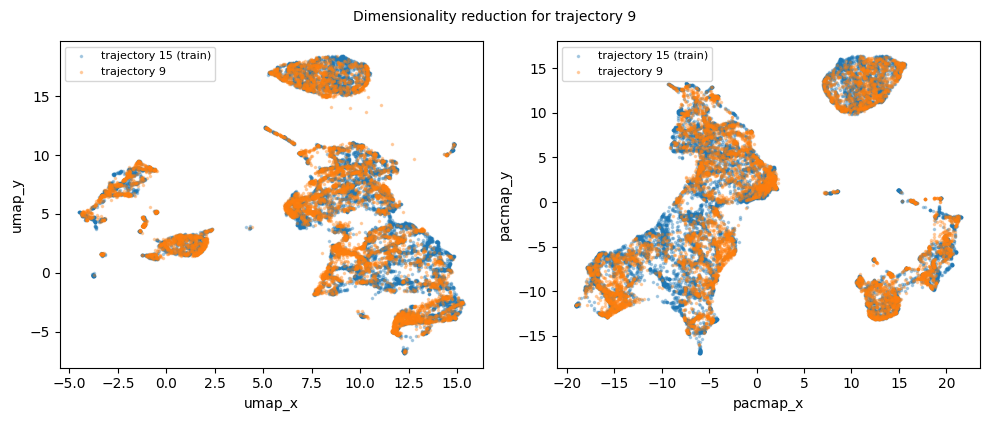

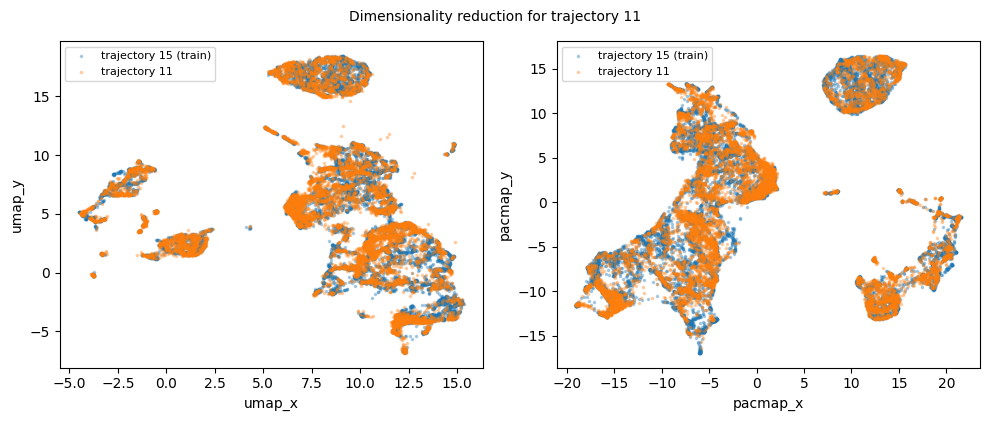

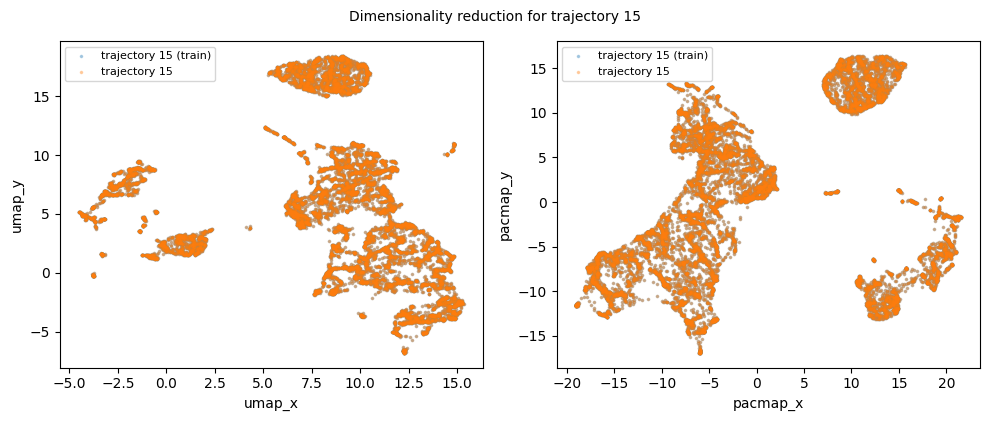

In [28]:
Clusters.plotEmbedding(nfigures=4)

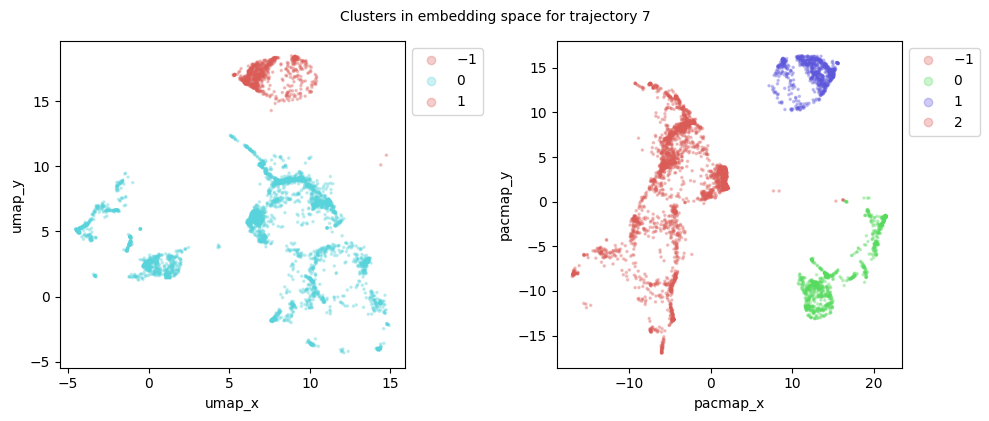

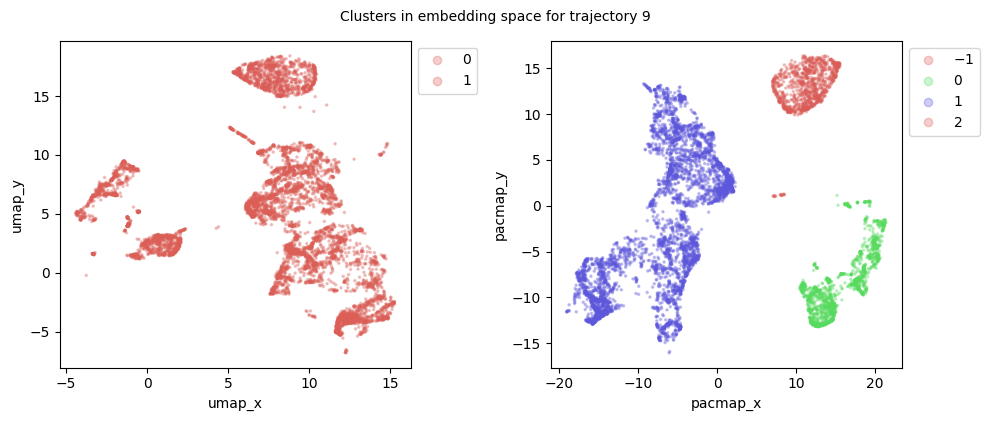

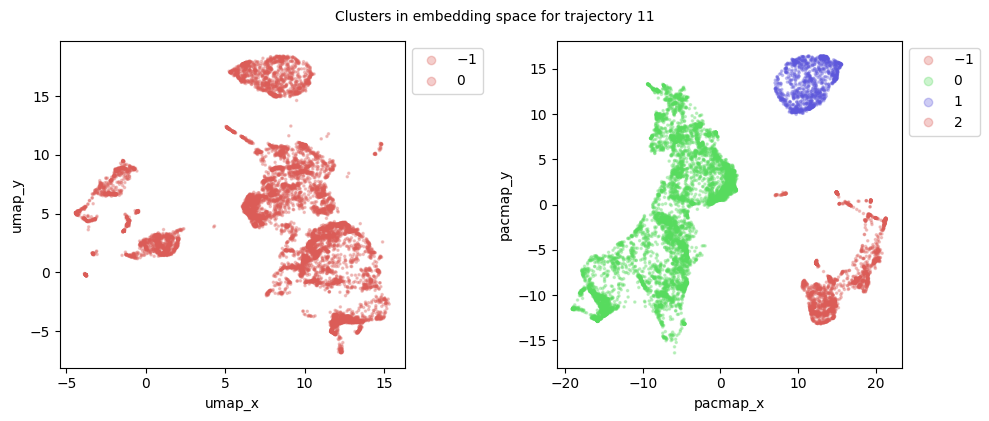

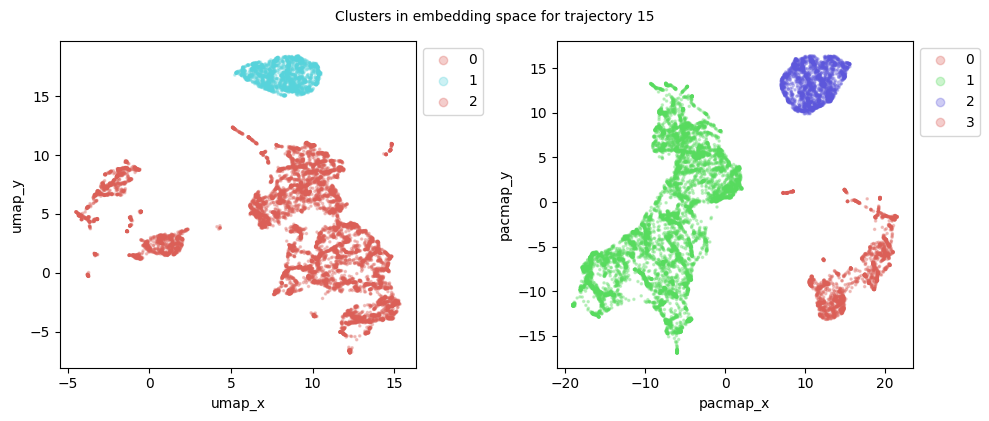

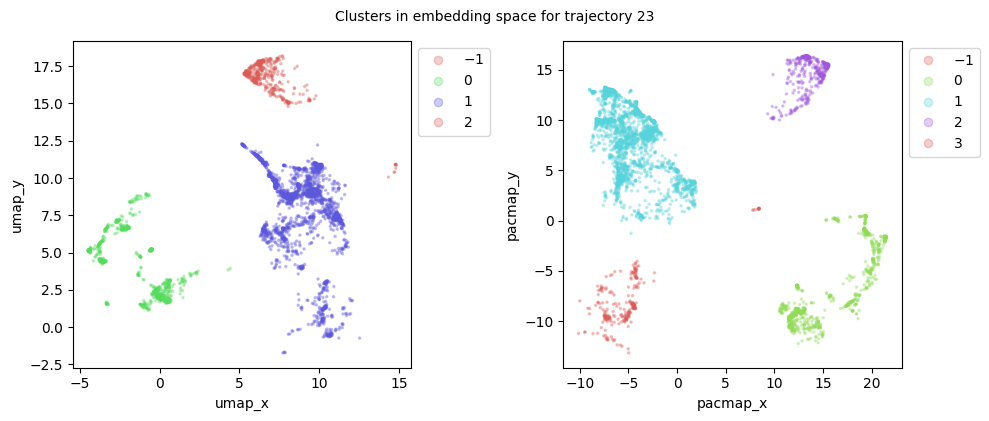

In [29]:
Clusters.plotResults(nfigures=5)

In [31]:
Clusters.getTrajectory(3).columns

Index(['nivel_tolva_compensacion(%)', 'rendimiento(ton)', 'Piñón_ext(°C)',
       'Piñón_int(°C)', 'Piñón_int(mm/s)', 'Piñón_ext(mm/s)',
       'Lubricación_retorno(°C)', 'Lubricación_depósito(°C)',
       'Lubricación_entrada(°C)', 'tiempo', 'cluster_umap', 'umap_x', 'umap_y',
       'cluster_pacmap', 'pacmap_x', 'pacmap_y'],
      dtype='object')

In [40]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 3, 
                    idxVariable     = 6, 
                    algorithm       = 'pacmap')